<a href="https://colab.research.google.com/github/mwetmore05/A05-pca/blob/main/A05PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maggie Wetmore

**Date:**  10/21/26

#1

In [3]:
# Your Phase 1 solution to the problem goes here.
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
#importing data
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

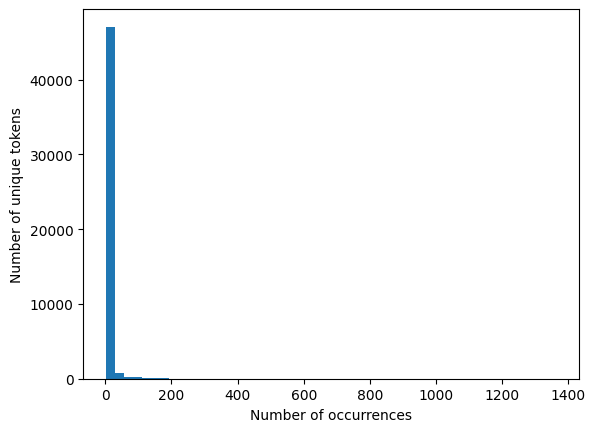

In [4]:
import matplotlib.pyplot as plt
#creating histogram
plt.hist(list(token_count.values()), bins=50)
plt.xlabel("Number of occurrences")
plt.ylabel("Number of unique tokens")
plt.show()

Most of the tokes occur few times and a small number occur very frequently. This histogram is STRONGlY right skewed with mos tof the tokens on the leftside.

#2

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
#setting up like in linear regression slides
data = pd.read_parquet('/content/Phishing_clean.parquet')
X = data.drop(columns='Email Type')
y = data['Email Type']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression().fit(X_train, y_train)
print(model.score(X_test, y_test))
print(model.score(X_train, y_train))
coef = pd.Series(model.coef_, index=X.columns)
coef.loc[coef.abs().sort_values(ascending=False).head(10).index]

0.6658718438847919
0.7670143724934355


,0
intervention,-1.259257
localized,0.824350
thermal,0.747006
crawler,0.696167
background-image:,-0.622909
"helvetica,",0.598560
aging,0.594956
form.,0.576886
gray;,-0.574480
a:active,0.574480


Regression has a test R^2 of .666 and trianing R^2 of .767. This means the model fits the training data better,

#3

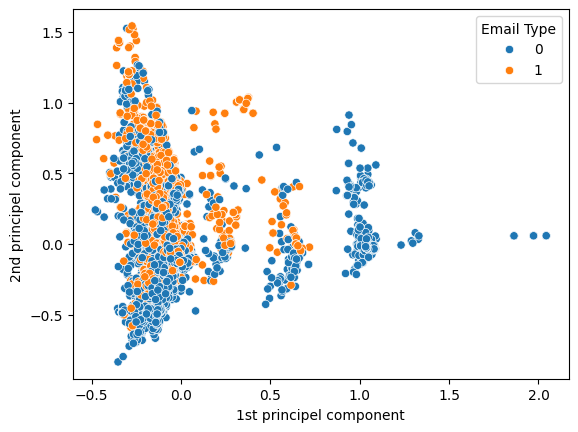

In [9]:
from sklearn.decomposition import PCA
import seaborn as sns
# paking the first pca like in the sldies
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y)
plt.xlabel("1st principel component")
plt.ylabel("2nd principel component")
plt.show()

the scam and non scam emails overlit, showing the 1st and 2nd principle components do not seperate them. Scam emails tend to have higher values on the 2nd component and clusters farther to the right are mostly non scam emails...

#4

In [11]:
pca2 = PCA(n_components=2610).fit(X_train)
X_train_pca = pca2.transform(X_train)
X_test_pca = pca2.transform(X_test)
model2 = LinearRegression().fit(X_train_pca, y_train) #setting this pca 2 (not the first one varibale name) like in the sldies
print(model2.score(X_train_pca, y_train))
print(model2.score(X_test_pca, y_test))

0.7662326827745849
0.6683390643101161



The PCA regression has a test R^2 of .668 and training R^2 of .766. Meaning the model fits the training data better. In comparison with Q2, the test R^2 is slightly higher and the training R^2 is slightly lower so performance is very similar with fewer variables.

#5

PCA combines features that contain overlapping info and makes them into new baraibles. This lets us keep fewer of the components and perserve a llot of the data variation. These compnenets scores can be used in regression which can reudce number of varaibles.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 5bae62f
- **AI tool and model used:** Chat GPT

### *Prompts used

1. For question 1, what can I do to enhance the code
2. Now for questioon2, what are main improvments I should make?
3. For question3 do you spot any errors or areas for main improvment?
4. For question 4 for any changes to be made or misinterpretations you spot?
5. now for 5 anything I can add or definitely add to enhance my answer to the question?


### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. For Q1, your code already works. To make the histogram easier to read, add a title and use a logarithmic y-axis so the smaller bars are visible:
plt.hist(list(token_count.values()), bins=50)plt.yscale("log")plt.xlabel("Number of occurrences")plt.ylabel("Number of unique tokens (log scale)")plt.title("Distribution of Token Occurrences")plt.show()


The log scale changes only the display, not the counts.

2. Your Q2 code works. The main improvements would be:
- Label the R² outputs so readers know which is which:print("Test R²:", model.score(X_test, y_test))print("Training R²:", model.score(X_train, y_train))
- Simplify the coefficient sorting for readability:coef = pd.Series(model.coef_, index=X.columns)largest = coef.abs().sort_values(ascending=False).head(10)coef.loc[largest.index]
- Explain the coefficient signs: positive values increase the predicted scam score; negative values decrease it, holding the other features fixed.
These improve presentation and interpretation without changing your results.

3. No major errors. You exclude Email Type from PCA, keep two components, and color the points by email type correctly.

The main improvements are:
- Reduce overlapping points: add alpha=0.5 to sns.scatterplot(...).
- Clarify the legend: label 0 as “Non-scam” and 1 as “Scam.”
- Soften the explanation: say the components “do not clearly separate the groups,” since some clusters are mostly non-scam but substantial overlap remains.

4. No major errors. You correctly fit PCA on the training data and transform both sets using that fitted PCA.

Two small improvements:
- Label the outputs: your code prints training R² first, then test R².
- Describe the results as very similar performance, with test R² slightly increasing from .666 to .668. This is a small improvement on this split, not proof that PCA always performs better.
Your explanation is otherwise correct.

5. Your answer covers the main advantage. You could add:

“Keeping fewer components also means estimating fewer regression coefficients, which can help reduce overfitting.”

To connect it to your results:

“Here, using 2,610 components gave nearly the same performance as using all 2,711 original features.”

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Keeps the data the same but make it easier to read and adds a title |
| 2 | Accept  | Accept both, saying which R is which is whatt I meant ot do, glad AI could enhance that also explaining the coefficents is necesary to improve interpretation |
|3|Modify|I am not going to change my explanaiton but reducing overlapping points and clairfying my legend does enhance my work so I accept that|
|4|Accept|Similar to previous response, I should have labeled which R is which. Also the edit on my description makes my interpretation better|
|5|Accept|Adds things to my interprettaion thta makes it better, and I should have added myself |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


#1

In [13]:
# Your Phase 1 solution to the problem goes here.
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
#importing data
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

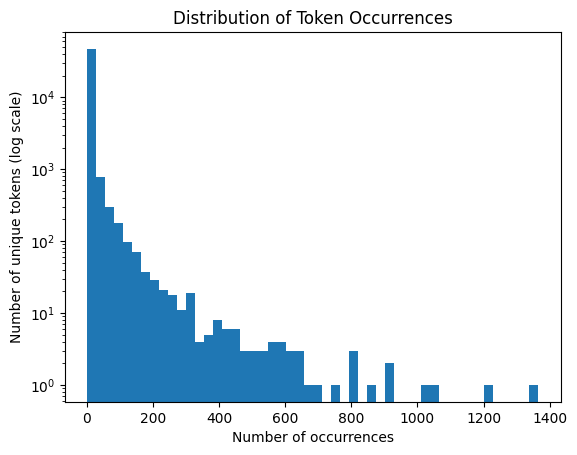

In [14]:
import matplotlib.pyplot as plt
#creating histogram
plt.hist(list(token_count.values()), bins=50)
plt.yscale("log") #suggested implemented
plt.xlabel("Number of occurrences")
plt.ylabel("Number of unique tokens (log scale)") #suggested implemented
plt.title("Distribution of Token Occurrences") #suggested implemented
plt.show()

Most of the tokes occur few times and a small number occur very frequently. This histogram is STRONGLY right skewed with mos tof the tokens on the leftside.

#2

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
#setting up like in linear regression slides
data = pd.read_parquet('/content/Phishing_clean.parquet')
X = data.drop(columns='Email Type')
y = data['Email Type']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression().fit(X_train, y_train)
print("Test R²:", model.score(X_test, y_test)) #suggested implemented
print("Training R²:", model.score(X_train, y_train)) #suggested implemented
coef = pd.Series(model.coef_, index=X.columns)
largest = coef.abs().sort_values(ascending=False).head(10) #ssuggested implemented
coef.loc[largest.index] #suggested implemented

Test R²: 0.6658718438847919
Training R²: 0.7670143724934355


,0
intervention,-1.259257
localized,0.824350
thermal,0.747006
crawler,0.696167
background-image:,-0.622909
"helvetica,",0.598560
aging,0.594956
form.,0.576886
gray;,-0.574480
a:active,0.574480


Regression has a test R^2 of .666 and trianing R^2 of .767. This means the model fits the training data better,
Positive coefficients increase the predicted scam score, while negative coefficients decrease it, holding the other features fixed.
*suggested implemented:

#3

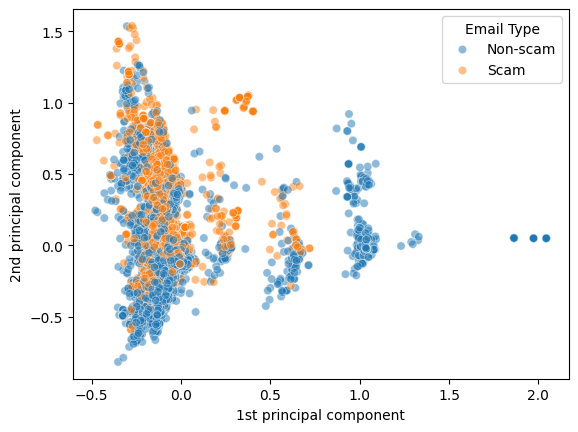

In [16]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)
#suggested implemented: clearer legend and reduced overlap
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=y.map({0: "Non-scam", 1: "Scam"}), alpha=0.5)
plt.xlabel("1st principal component")
plt.ylabel("2nd principal component")
plt.show()

the scam and non scam emails overlif, showing the 1st and 2nd principle components do not seperate them. Scam emails tend to have higher values on the 2nd component and clusters farther to the right are mostly non scam emails...

#4

In [17]:
pca2 = PCA(n_components=2610).fit(X_train)
X_train_pca = pca2.transform(X_train)
X_test_pca = pca2.transform(X_test)
model2 = LinearRegression().fit(X_train_pca, y_train)
print("Training R²:", model2.score(X_train_pca, y_train)) #suggested implemented
print("Test R²:", model2.score(X_test_pca, y_test)) #suggested implemented

Training R²: 0.7662326827745849
Test R²: 0.6683390643101161


The PCA regression has a test R^2 of .668 and training R^2 of .766. Meaning the model fits the training data better. In comparison with Q2, the test R^2 is slightly higher and the training R^2 is slightly lower so performance is very similar with fewer variables.
This is a small improvement on this split, rather than evidence that PCA is generally better. *suggested implemented

#5

PCA combines features that contain overlapping info and makes them into new variables. This lets us keep fewer of the components and perserve a lot of the data variation. These componenets scores can be used in regression which can reduce number of varaibles.
Keeping fewer components  means estimating fewer regression coefficients which can help reduce overfitting. Like here using 2,610 components gave nearly the same performance as using all 2,711 original features. *suggested implemented

### *Reflection on AI assistance
In your own words without generative AI.

AI helped me improve how I presented my overall work and code. It also helped me explain my result better, drawing data insights from areas I missed on. For Q1, I added a title and changed the vertical axis to a log scale so that the smaller bars were easier to see for any audience. For Q2, I labeled the training and test R^2 values and explained what positive and negative coefficients mean. For Q3, I made the points more transparent and changed the legend labels. For Q4, I labeled the results and clarified that the small increase in test R62, like in Q2. For Q5, I added that fewer components mean fewer coefficients to estimate  which can help reduce overfitting-- making it  a better explanation and draawing on insigths I forgot.
One limitation was that AI did not give me a ton of code enhancements, but I think I ask very specific wuestioons and only ask for necesary change sthat the work remains my own. I verified the final solution by running the code and checking the outputs and graphs. The Q2 results stayed the same after the presentation changes. I also checked that PCA was fitted on the training data before transforming the test data. I also verified AI's suggested with the class slide shows that I worked to build my code off of.